<a href="https://colab.research.google.com/github/novaladriann/Kelompok-4_K-Means_IBM-HR-Employee-Attrition/blob/main/notebook/01_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1 - Eksplorasi Data (EDA)

**Kelas dan paket:** 5B-4 - IBM HR Employee Attrition  
**Metode kelompok: Klastering (K-Means)**  
**Cakupan:** Eksplorasi Data (*Exploratory Data Analysis*, EDA) dan keputusan awal praproses.

Notebook ini memuat pemeriksaan struktur dan mutu dataset, analisis sebaran variabel, evaluasi calon fitur segmentasi, serta penyusunan dataset bersih. Penentuan jumlah klaster dan pelatihan K-Means dilakukan pada tahap pemodelan.

**Catatan analisis:** nilai kuantitatif yang dijelaskan di bawah merujuk pada hasil pemeriksaan dataset kelompok sebelumnya. Setiap hasil perlu dicocokkan dengan keluaran terbaru setelah notebook dijalankan ulang dari awal.

## Langkah 0 - Pemahaman sumber dan konteks dataset

Dataset **IBM HR Employee Attrition** diperoleh dari [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) dan berisi atribut demografis serta pekerjaan karyawan. Dataset ini merupakan data **sintetis**, sehingga hasil analisis digunakan untuk latihan metode dan tidak menggambarkan kondisi karyawan di perusahaan tertentu secara langsung.

**Unit analisis:** setiap baris merepresentasikan satu karyawan.

**Rumusan pertanyaan analitik:** *Berapa kelompok karyawan yang dapat dibentuk berdasarkan karakteristik pekerjaan dan pengalaman kerja, serta bagaimana karakteristik masing-masing kelompok?*

Metode K-Means digunakan untuk menemukan pola pengelompokan tanpa label target. Kolom `Attrition` tidak digunakan untuk membentuk klaster, tetapi dapat dianalisis setelah klaster terbentuk untuk memberikan konteks deskriptif.

**Batasan:** dataset tidak menjelaskan penyebab keluarnya karyawan. Arti dan satuan beberapa atribut perlu merujuk pada dokumentasi sumber; informasi yang belum terverifikasi tidak diasumsikan sendiri.

## Langkah 1 — Pemuatan dataset
Dataset dibaca menggunakan `pandas`. Pengecekan awal mencakup lokasi berkas, pengodean karakter (*encoding*), nama kolom, serta jumlah baris dan kolom. Pemeriksaan ini diperlukan agar proses EDA menggunakan berkas dan struktur data yang benar.

In [23]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

nama_file = "IBM_HR_Employee_Attrition.csv"

calon_path = [
    Path("../data") / nama_file,
    Path("data") / nama_file,
]

path_dataset = next((p for p in calon_path if p.is_file()), None)

if path_dataset is None:
    raise FileNotFoundError(
        f"Tidak menemukan {nama_file} di folder data/. "
        "Letakkan CSV mentah di sana atau ubah PATH di notebook."
    )

# utf-8-sig mengatasi tanda BOM pada awal file yang pernah ditemukan.
# na_values hanya mengidentifikasi kemungkinan simbol data hilang.
df = pd.read_csv(
    path_dataset,
    encoding="utf-8-sig",
    na_values=["?", "---", "NA", "n/a", "unknown", " ", ""],
)

folder_data = path_dataset.parent
print("Direktori kerja :", Path.cwd())
print("Lokasi berkas   :", path_dataset)
print("Ukuran dataset :", df.shape)
print("Kolom pertama  :", df.columns[0])

Direktori kerja : c:\Users\noval\Kelompok-4_K-Means_IBM-HR-Employee-Attrition\notebook
Lokasi berkas   : ..\data\IBM_HR_Employee_Attrition.csv
Ukuran dataset : (1470, 35)
Kolom pertama  : Age


**Hasil pemeriksaan.** Pada pembacaan awal, dataset memuat **1.470 baris dan 35 kolom** dengan kolom pertama bernama `Age`. Struktur tersebut sesuai dengan informasi paket dataset yang digunakan.

**Interpretasi.** Data berhasil dipisahkan menjadi kolom-kolom yang semestinya. Penggunaan `utf-8-sig` menghindari munculnya karakter BOM pada awal nama kolom.

**Keputusan.** Dataset dapat digunakan untuk pemeriksaan struktur dan kualitas data berikutnya. Jika ukuran pada eksekusi terbaru berbeda, perubahan tersebut harus ditelusuri sebelum melanjutkan analisis.

## Langkah 2 — Pemeriksaan struktur dan tipe data
Pemeriksaan dilakukan menggunakan `head()`, `info()`, dan `describe()`. Tujuannya adalah mengidentifikasi struktur tabel, rentang nilai, serta perbedaan antara tipe data yang terbaca oleh Python dan makna analitis setiap variabel.

In [24]:
# head() memperlihatkan 10 contoh isi data agar formatnya bisa diperiksa.
display(df.head(10))

# info() menampilkan jumlah non-null dan tipe data tiap kolom.
df.info()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [25]:
# Statistik ringkas untuk kolom angka: rata-rata, median, min, max, dll.
display(df.describe().round(2))

# Statistik ringkas untuk kolom kategori: jenis, kategori dominan, frekuensi.
display(df.describe(include="object"))

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.00,1470.00,1470.00,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,...,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,36.92,802.49,9.19,2.91,1.0,1024.87,2.72,65.89,2.73,2.06,...,2.71,80.0,0.79,11.28,2.80,2.76,7.01,4.23,2.19,4.12
std,9.14,403.51,8.11,1.02,0.0,602.02,1.09,20.33,0.71,1.11,...,1.08,0.0,0.85,7.78,1.29,0.71,6.13,3.62,3.22,3.57
min,18.00,102.00,1.00,1.00,1.0,1.00,1.00,30.00,1.00,1.00,...,1.00,80.0,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,30.00,465.00,2.00,2.00,1.0,491.25,2.00,48.00,2.00,1.00,...,2.00,80.0,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00
50%,36.00,802.00,7.00,3.00,1.0,1020.50,3.00,66.00,3.00,2.00,...,3.00,80.0,1.00,10.00,3.00,3.00,5.00,3.00,1.00,3.00
75%,43.00,1157.00,14.00,4.00,1.0,1555.75,4.00,83.75,3.00,3.00,...,4.00,80.0,1.00,15.00,3.00,3.00,9.00,7.00,3.00,7.00
max,60.00,1499.00,29.00,5.00,1.0,2068.00,4.00,100.00,4.00,5.00,...,4.00,80.0,3.00,40.00,6.00,4.00,40.00,18.00,15.00,17.00


,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


**Temuan.** Sebagian besar atribut berbentuk numerik, tetapi beberapa kolom seperti `Education`, `JobSatisfaction`, `EnvironmentSatisfaction`, dan `JobInvolvement` merupakan nilai **ordinal** yang menyatakan tingkatan atau skor. Dataset juga memiliki kolom kategori seperti `Department`, `JobRole`, dan `Attrition`.

**Interpretasi.** Tipe `int64` tidak selalu berarti variabel berskala kontinu. Skor ordinal memiliki urutan, tetapi jarak antarlevel belum tentu setara.

**Implikasi.** Penggunaan skor ordinal sebagai fitur numerik pada K-Means harus dinyatakan sebagai penyederhanaan dan diperhatikan saat menafsirkan jarak antarkaryawan.

## Langkah 3 — Pemeriksaan kualitas data

Pemeriksaan mutu data meliputi nilai hilang, nilai hilang tersamar, baris duplikat, kolom konstan, identifier, nilai tidak logis, pencilan, dan konsistensi kategori. Pembersihan data dilakukan berdasarkan hasil pemeriksaan, bukan dengan menghapus data secara otomatis.

### 3a. Pemeriksaan nilai hilang

In [26]:
# isna() menghasilkan True untuk sel yang kosong/NaN.
# sum() menghitung banyaknya True pada setiap kolom.
jumlah_hilang = df.isna().sum()
persen_hilang = df.isna().mean() * 100

tabel_hilang = pd.DataFrame({
    "jumlah": jumlah_hilang,
    "persen": persen_hilang.round(2),
}).sort_values("jumlah", ascending=False)

print("Total sel yang hilang:", int(jumlah_hilang.sum()))
print("Kolom yang memiliki nilai hilang:",
      list(tabel_hilang[tabel_hilang["jumlah"] > 0].index) or "Tidak ada")
display(tabel_hilang)

Total sel yang hilang: 0
Kolom yang memiliki nilai hilang: Tidak ada


,jumlah,persen
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


**Temuan.** Pemeriksaan awal menunjukkan **0 sel bernilai hilang (`NaN`)** pada 35 kolom.

**Interpretasi.** Tidak ditemukan kekosongan eksplisit pada dataset yang digunakan. Temuan ini belum menutup kemungkinan adanya penanda nilai hilang yang tersamar sebagai teks atau angka tertentu.

**Keputusan.** Tidak diperlukan imputasi untuk nilai `NaN` pada data awal. Pemeriksaan dilanjutkan terhadap penanda hilang tersamar.

### 3b. Pemeriksaan nilai hilang tersamar

Selain `NaN`, nilai hilang dapat muncul dalam bentuk teks atau angka khusus. Pada dataset kepegawaian, angka nol tidak selalu menunjukkan data hilang; misalnya, `YearsAtCompany = 0` dapat merepresentasikan karyawan yang baru bergabung. Oleh karena itu, validitas nilai diperiksa berdasarkan konteks kolom.

In [27]:
# Kolom yang secara logika seharusnya lebih besar dari nol.
kolom_tidak_boleh_nol = [
    "Age", "DailyRate", "HourlyRate", "MonthlyIncome",
    "MonthlyRate", "JobLevel", "Education", "StandardHours"
]

for nama_kolom in kolom_tidak_boleh_nol:
    jumlah_nol = (df[nama_kolom] == 0).sum()
    print(f"{nama_kolom:25s} | jumlah nol: {jumlah_nol:4d} | min: {df[nama_kolom].min()}")

# Beberapa kolom justru dapat memiliki nilai nol yang bermakna.
kolom_nol_sah = [
    "NumCompaniesWorked", "StockOptionLevel", "TrainingTimesLastYear",
    "YearsAtCompany", "YearsSinceLastPromotion", "TotalWorkingYears"
]

print("\nKolom yang memungkinkan nilai nol:")
for nama_kolom in kolom_nol_sah:
    print(nama_kolom, "->", int((df[nama_kolom] == 0).sum()), "baris")

Age                       | jumlah nol:    0 | min: 18
DailyRate                 | jumlah nol:    0 | min: 102
HourlyRate                | jumlah nol:    0 | min: 30
MonthlyIncome             | jumlah nol:    0 | min: 1009
MonthlyRate               | jumlah nol:    0 | min: 2094
JobLevel                  | jumlah nol:    0 | min: 1
Education                 | jumlah nol:    0 | min: 1
StandardHours             | jumlah nol:    0 | min: 80

Kolom yang memungkinkan nilai nol:
NumCompaniesWorked -> 197 baris
StockOptionLevel -> 631 baris
TrainingTimesLastYear -> 54 baris
YearsAtCompany -> 44 baris
YearsSinceLastPromotion -> 581 baris
TotalWorkingYears -> 11 baris


In [28]:
# Tampilkan nilai-nilai unik dari tiap kolom teks.
# Ini berguna untuk menemukan '?' atau label yang tak konsisten.
for nama_kolom in df.select_dtypes(include="object").columns:
    print(nama_kolom, "->", df[nama_kolom].dropna().unique(), "\n")

Attrition -> ['Yes' 'No'] 

BusinessTravel -> ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel'] 

Department -> ['Sales' 'Research & Development' 'Human Resources'] 

EducationField -> ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources'] 

Gender -> ['Female' 'Male'] 

JobRole -> ['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources'] 

MaritalStatus -> ['Single' 'Married' 'Divorced'] 

Over18 -> ['Y'] 

OverTime -> ['Yes' 'No'] 



**Temuan.** Pemeriksaan awal tidak menunjukkan nilai nol pada kolom yang secara logis harus bernilai positif. Sejumlah nilai nol muncul pada atribut seperti `YearsAtCompany` dan `StockOptionLevel`, yang masih dapat memiliki makna sah.

**Interpretasi.** Nilai nol harus dibedakan dari data yang tidak diketahui. Mengganti seluruh angka nol dengan `NaN` justru dapat mengubah informasi yang valid.

**Keputusan.** Nilai nol yang masih sesuai dengan definisi atribut dipertahankan. Tidak dilakukan imputasi atau penghapusan berdasarkan nilai nol semata.

### 3c. Pemeriksaan duplikat

Duplikasi diperiksa dalam dua bentuk, yaitu baris dengan seluruh nilai yang identik dan penggunaan `EmployeeNumber` secara berulang. Pemeriksaan kedua diperlukan untuk memastikan satu karyawan tidak terwakili lebih dari sekali tanpa alasan yang jelas.

In [29]:
jumlah_duplikat = int(df.duplicated().sum())
jumlah_id_berulang = int(df["EmployeeNumber"].duplicated().sum())

print("Baris duplikat identik    :", jumlah_duplikat)
print("EmployeeNumber berulang :", jumlah_id_berulang)

Baris duplikat identik    : 0
EmployeeNumber berulang : 0


**Temuan.** Ditemukan **0 baris identik** dan **0 pengulangan `EmployeeNumber`** pada hasil pemeriksaan awal.

**Interpretasi.** Tidak terdapat indikasi duplikasi berdasarkan dua kriteria yang diuji.

**Keputusan.** Tidak ada baris yang dihapus pada tahap ini. Jika ditemukan pengulangan pada versi data lain, penyebabnya perlu diperiksa sebelum menghapus baris.

### 3d. Pemeriksaan kolom konstan dan identifier

Kolom konstan tidak memiliki variasi antarobservasi dan tidak membantu membedakan profil karyawan. Identifier digunakan untuk mengenali baris data, tetapi bukan karakteristik yang relevan bagi pengukuran jarak pada K-Means.

In [30]:
jumlah_unik = df.nunique(dropna=False)
kolom_konstan = jumlah_unik[jumlah_unik <= 1].index.tolist()
kolom_hampir_unik = jumlah_unik[jumlah_unik > 0.90 * len(df)].index.tolist()

print("Kolom konstan         :", kolom_konstan)
print("Kolom >90% nilai unik :", kolom_hampir_unik)
print("Nilai unik EmployeeNumber:", int(df["EmployeeNumber"].nunique()))

Kolom konstan         : ['EmployeeCount', 'Over18', 'StandardHours']
Kolom >90% nilai unik : ['EmployeeNumber', 'MonthlyIncome', 'MonthlyRate']
Nilai unik EmployeeNumber: 1470


**Temuan.** Tiga kolom yang memiliki satu nilai unik adalah `EmployeeCount`, `StandardHours`, dan `Over18`. Kolom `EmployeeNumber` memiliki **1.470 nilai unik**.

**Interpretasi.** Ketiga kolom konstan tidak memberikan informasi pembeda. Sementara itu, `EmployeeNumber` berfungsi sebagai identitas karyawan, bukan ukuran karakteristik kerja. Banyaknya nilai unik pada `MonthlyIncome` atau `MonthlyRate` tidak dengan sendirinya menjadikan kedua kolom tersebut identifier.

**Keputusan.** Ketiga kolom konstan dikeluarkan dari dataset bersih. `EmployeeNumber` tetap tersedia untuk penelusuran, tetapi tidak dimasukkan ke fitur K-Means.

### 3e. Pemeriksaan nilai tidak logis dan pencilan (*outlier*)

Pemeriksaan nilai tidak logis dilakukan menggunakan aturan konsistensi antarkolom, misalnya lama bekerja pada jabatan tertentu tidak boleh melebihi masa kerja di perusahaan. Pencilan numerik diperiksa menggunakan metode **Interquartile Range (IQR)**. Hasil IQR menunjukkan nilai yang perlu ditinjau, bukan bukti bahwa data tersebut salah.

In [31]:
# Pemeriksaan aturan yang seharusnya konsisten antar kolom.
pemeriksaan_logika = {
    "YearsAtCompany > TotalWorkingYears":
        (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum(),
    "YearsInCurrentRole > YearsAtCompany":
        (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum(),
    "YearsWithCurrManager > YearsAtCompany":
        (df["YearsWithCurrManager"] > df["YearsAtCompany"]).sum(),
    "YearsSinceLastPromotion > YearsAtCompany":
        (df["YearsSinceLastPromotion"] > df["YearsAtCompany"]).sum(),
    "Perkiraan usia mulai kerja <14":
        ((df["Age"] - df["TotalWorkingYears"]) < 14).sum(),
}

for nama_pemeriksaan, jumlah in pemeriksaan_logika.items():
    print(nama_pemeriksaan, "->", int(jumlah), "baris")

print("Rentang usia:", df["Age"].min(), "-", df["Age"].max())

YearsAtCompany > TotalWorkingYears -> 0 baris
YearsInCurrentRole > YearsAtCompany -> 0 baris
YearsWithCurrManager > YearsAtCompany -> 0 baris
YearsSinceLastPromotion > YearsAtCompany -> 0 baris
Perkiraan usia mulai kerja <14 -> 0 baris
Rentang usia: 18 - 60


In [32]:
# IQR = kuartil 3 (Q3) - kuartil 1 (Q1).
# Kandidat pencilan: nilai < Q1 - 1.5*IQR atau > Q3 + 1.5*IQR.
kolom_pencilan = [
    "Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
    "YearsSinceLastPromotion", "NumCompaniesWorked", "DistanceFromHome",
    "PercentSalaryHike", "TrainingTimesLastYear"
]

hasil_pencilan = []
for nama_kolom in kolom_pencilan:
    nilai = df[nama_kolom]

    q1 = nilai.quantile(0.25)
    q3 = nilai.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah_pencilan = ((nilai < batas_bawah) | (nilai > batas_atas)).sum()

    hasil_pencilan.append({
        "kolom": nama_kolom,
        "min": nilai.min(),
        "max": nilai.max(),
        "jumlah_pencilan": int(jumlah_pencilan),
        "persen_pencilan": round(jumlah_pencilan / len(df) * 100, 1),
        "skewness": round(nilai.skew(), 2),
    })

tabel_pencilan = pd.DataFrame(hasil_pencilan)
display(tabel_pencilan)

,kolom,min,max,jumlah_pencilan,persen_pencilan,skewness
0,Age,18,60,0,0.0,0.41
1,MonthlyIncome,1009,19999,114,7.8,1.37
2,TotalWorkingYears,0,40,63,4.3,1.12
3,YearsAtCompany,0,40,104,7.1,1.76
4,YearsSinceLastPromotion,0,15,107,7.3,1.98
5,NumCompaniesWorked,0,9,52,3.5,1.03
6,DistanceFromHome,1,29,0,0.0,0.96
7,PercentSalaryHike,11,25,0,0.0,0.82
8,TrainingTimesLastYear,0,6,238,16.2,0.55


**Temuan.** Pada pemeriksaan awal, tidak ditemukan pelanggaran aturan masa kerja yang diuji. Nilai usia berada pada rentang **18–60 tahun**. Berdasarkan metode IQR, `MonthlyIncome` memiliki **114 kandidat pencilan (7,8% dari 1.470 baris)**. Beberapa atribut masa kerja juga menunjukkan nilai ekstrem.

**Interpretasi.** Pendapatan yang relatif tinggi belum tentu merupakan kesalahan. Pada data kepegawaian, nilai ekstrem dapat berkaitan dengan perbedaan tingkat jabatan atau lama pengalaman, tetapi hubungan tersebut perlu diuji lebih lanjut.

**Keputusan.** Kandidat pencilan tidak dihapus secara otomatis pada tahap EDA. Dampaknya terhadap pembentukan pusat klaster akan diperiksa dalam eksperimen berikutnya.

### 3f. Pemeriksaan konsistensi kategori

Kolom kategori diperiksa untuk mendeteksi perbedaan penulisan yang tidak bermakna, seperti spasi tambahan dan variasi huruf besar-kecil. Hasil pemeriksaan digunakan sebagai dasar keputusan standardisasi label.

In [33]:
hasil_konsistensi = []

for nama_kolom in df.select_dtypes(include="object").columns:
    label_asli = df[nama_kolom].dropna().astype(str)
    label_normal = label_asli.str.strip().str.casefold()

    jumlah_spasi = (label_asli != label_asli.str.strip()).sum()
    perbedaan_kategori = label_asli.nunique() - label_normal.nunique()

    hasil_konsistensi.append({
        "kolom": nama_kolom,
        "baris_bermasalah_spasi": int(jumlah_spasi),
        "kategori_ganda_penulisan": int(perbedaan_kategori),
    })

tabel_konsistensi = pd.DataFrame(hasil_konsistensi)
display(tabel_konsistensi)

,kolom,baris_bermasalah_spasi,kategori_ganda_penulisan
0,Attrition,0,0
1,BusinessTravel,0,0
2,Department,0,0
3,EducationField,0,0
4,Gender,0,0
5,JobRole,0,0
6,MaritalStatus,0,0
7,Over18,0,0
8,OverTime,0,0


**Interpretasi hasil.** Tabel menampilkan jumlah baris dengan spasi berlebih serta indikasi kategori ganda akibat perbedaan kapitalisasi. Nilai nol berarti tidak terdeteksi masalah **menurut kriteria pemeriksaan tersebut**.

**Keputusan.** Normalisasi kategori hanya dilakukan apabila ditemukan ketidakkonsistenan nyata. Kategori tidak digabungkan otomatis hanya berdasarkan kemiripan penulisan. Kesimpulan akhir mengikuti tabel hasil eksekusi terbaru.

## Langkah 4 — Penentuan fitur kandidat untuk K-Means

Pemilihan fitur dilakukan berdasarkan tujuan segmentasi, yaitu mengenali kemiripan profil karyawan dari aspek usia, pendapatan, pengalaman kerja, jarak tempat tinggal, kepuasan, keterlibatan, dan lembur. Pada tahap ini ditetapkan **12 fitur kandidat** yang terdiri atas 11 atribut numerik/ordinal dan satu indikator biner (`OverTime_Yes`).

Kolom `Attrition`, `JobRole`, `Department`, `JobLevel`, `Gender`, dan `MaritalStatus` disiapkan sebagai bahan penafsiran setelah klaster terbentuk. Penentuan jumlah klaster dilakukan pada tahap pemodelan.

In [34]:
# 11 fitur numerik/ordinal. Sesuai pilihan fitur pada notebook awal.
fitur_numerik = [
    "Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
    "YearsSinceLastPromotion", "NumCompaniesWorked", "DistanceFromHome",
    "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
    "JobInvolvement",
]

# Kolom ini BUKAN fitur pembentuk klaster.
bahan_interpretasi = [
    "Attrition", "JobRole", "Department", "JobLevel", "Gender", "MaritalStatus"
]

# Buat matriks kandidat fitur secara terpisah dari df mentah.
X = df[fitur_numerik].copy()
X["OverTime_Yes"] = (df["OverTime"] == "Yes").astype(int)

print("Jumlah baris dan fitur kandidat:", X.shape)
display(X.describe().T.round(2))

Jumlah baris dan fitur kandidat: (1470, 12)


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.0,36.0,43.0,60.0
MonthlyIncome,1470.0,6502.93,4707.96,1009.0,2911.0,4919.0,8379.0,19999.0
TotalWorkingYears,1470.0,11.28,7.78,0.0,6.0,10.0,15.0,40.0
YearsAtCompany,1470.0,7.01,6.13,0.0,3.0,5.0,9.0,40.0
YearsSinceLastPromotion,1470.0,2.19,3.22,0.0,0.0,1.0,3.0,15.0
NumCompaniesWorked,1470.0,2.69,2.50,0.0,1.0,2.0,4.0,9.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.0,7.0,14.0,29.0
JobSatisfaction,1470.0,2.73,1.10,1.0,2.0,3.0,4.0,4.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.0,3.0,4.0,4.0
WorkLifeBalance,1470.0,2.76,0.71,1.0,2.0,3.0,3.0,4.0


**Dasar pemilihan fitur**. Pemilihan fitur awal dilakukan berdasarkan relevansi atribut terhadap tujuan segmentasi profil karyawan. Atribut yang digunakan mencakup usia, pendapatan, pengalaman kerja, jarak tempat tinggal, kepuasan, keterlibatan kerja, dan status lembur.

Beberapa atribut lain, seperti `JobLevel`, `YearsInCurrentRole`, dan `YearsWithCurrManager`, disiapkan sebagai variabel pembanding karena berpotensi memiliki hubungan dengan atribut pengalaman kerja dan kompensasi yang telah dipilih.

`DailyRate`, `HourlyRate`, dan `MonthlyRate` tidak digunakan karena definisi bisnisnya belum dapat dipastikan secara memadai dari dokumentasi sumber. Sementara itu, skor kepuasan berskala 1–4 diperlakukan sebagai variabel numerik dengan mempertimbangkan keterbatasan skala ordinal.

**Keputusan**. Sebanyak 12 fitur ditetapkan sebagai kandidat awal segmentasi. Hubungan antarfitur akan diperiksa lebih lanjut melalui analisis korelasi pada tahap berikutnya.

## Langkah 5 — Pemeriksaan hubungan antarfitur

Analisis korelasi Pearson digunakan untuk melihat hubungan linear antara fitur kandidat dan beberapa atribut pembanding. Pada K-Means, penggunaan beberapa fitur yang sangat berkaitan dapat membuat dimensi tertentu lebih dominan dalam perhitungan jarak, walaupun fitur telah diskalakan.

Karena metode ini tidak menggunakan variabel target, `Attrition` tidak disertakan dalam matriks fitur. Kolom tersebut hanya digunakan untuk mendeskripsikan profil klaster setelah pemodelan.

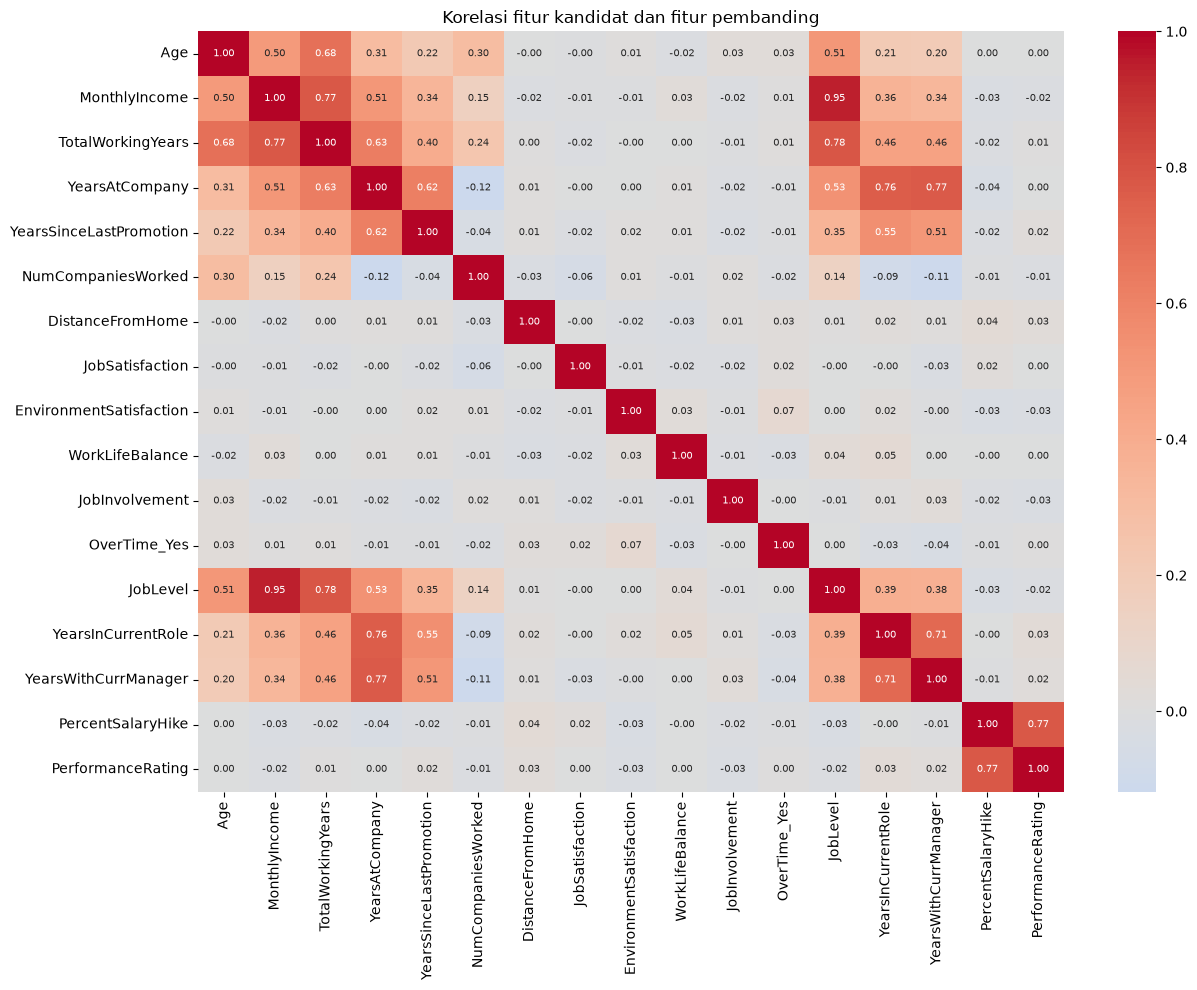

In [35]:
# Gunakan seluruh fitur X (termasuk OverTime_Yes), lalu tambahkan
# kandidat pembanding yang tidak dipakai pada model dasar.
fitur_pembanding = [
    "JobLevel", "YearsInCurrentRole", "YearsWithCurrManager",
    "PercentSalaryHike", "PerformanceRating",
]
data_korelasi = pd.concat([X, df[fitur_pembanding]], axis=1)
matriks_korelasi = data_korelasi.corr(numeric_only=True)

plt.figure(figsize=(13, 10))
sns.heatmap(
    matriks_korelasi,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
)
plt.title("Korelasi fitur kandidat dan fitur pembanding")
plt.tight_layout()
plt.show()

In [36]:
# Cari pasangan fitur dengan korelasi absolut > 0.70.
# Hanya ambil bagian atas matriks agar pasangan tidak dihitung dua kali.
mask_segitiga_atas = np.triu(
    np.ones(matriks_korelasi.shape, dtype=bool), k=1
)
pasangan_korelasi = matriks_korelasi.abs().where(mask_segitiga_atas).stack()

print("Semua pasangan dengan |r| > 0.70:")
print(pasangan_korelasi[pasangan_korelasi > 0.70]
      .sort_values(ascending=False).round(3))

# Secara khusus periksa fitur yang masuk ke X.
nama_fitur_x = set(X.columns)
mask_pasangan_x = [
    kolom_a in nama_fitur_x and kolom_b in nama_fitur_x
    for kolom_a, kolom_b in pasangan_korelasi.index
]
pasangan_dalam_x = pasangan_korelasi[mask_pasangan_x]

print("\nPasangan antarfitur X dengan |r| > 0.80:")
print(pasangan_dalam_x[pasangan_dalam_x > 0.80].round(3))

Semua pasangan dengan |r| > 0.70:
MonthlyIncome       JobLevel                0.950
TotalWorkingYears   JobLevel                0.782
PercentSalaryHike   PerformanceRating       0.774
MonthlyIncome       TotalWorkingYears       0.773
YearsAtCompany      YearsWithCurrManager    0.769
                    YearsInCurrentRole      0.759
YearsInCurrentRole  YearsWithCurrManager    0.714
dtype: float64

Pasangan antarfitur X dengan |r| > 0.80:
Series([], dtype: float64)


**Temuan**. Berdasarkan hasil perhitungan korelasi Pearson, ditemukan hubungan positif yang sangat kuat antara `JobLevel` dan `MonthlyIncome`, dengan koefisien korelasi sekitar 0,95. Selain itu, `MonthlyIncome` dan `TotalWorkingYears` menunjukkan korelasi positif sekitar 0,77.

**Interpretasi**. Korelasi tersebut menunjukkan bahwa beberapa atribut yang berkaitan dengan jenjang pekerjaan, kompensasi, dan pengalaman kerja memiliki hubungan linear cukup kuat. Pada metode K-Means, penggunaan beberapa fitur yang sangat berkaitan berpotensi memberikan pengaruh berlebihan pada dimensi tertentu dalam perhitungan jarak.

Keputusan. `JobLevel` tidak dimasukkan ke dalam fitur segmentasi awal untuk mengurangi potensi pengulangan informasi yang berkaitan dengan tingkat jabatan dan pendapatan. Atribut tersebut tetap disimpan sebagai bahan interpretasi klaster. Keputusan pemilihan fitur akan dievaluasi kembali melalui eksperimen perbandingan himpunan fitur.

## Langkah 6 — Visualisasi data

Visualisasi digunakan untuk memeriksa pola sebaran fitur, calon pencilan, perbedaan skala, dan distribusi atribut pendukung. Setiap grafik diikuti interpretasi yang berkaitan langsung dengan keputusan praproses.

### 6a. Distribusi fitur kandidat

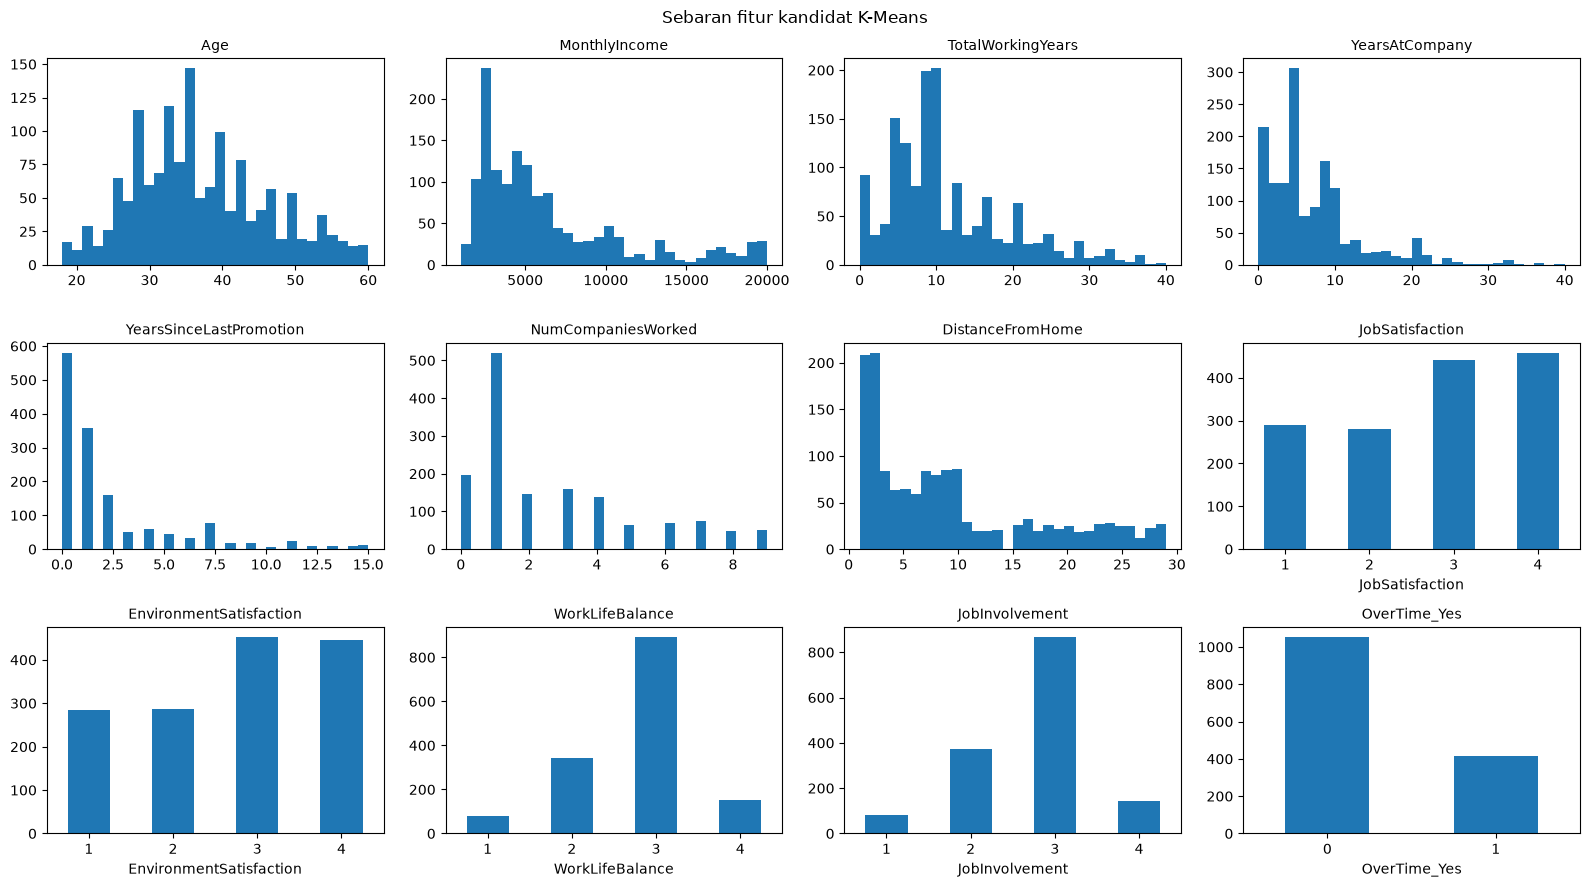

In [37]:
# Tampilkan sebaran dari 12 calon fitur dalam satu panel.
fig, axes = plt.subplots(3, 4, figsize=(16, 9))

for ax, nama_kolom in zip(axes.ravel(), X.columns):
    nilai = X[nama_kolom]

    # Variabel dengan kategori sedikit lebih jelas dengan diagram batang.
    if nilai.nunique() <= 5:
        nilai.value_counts().sort_index().plot.bar(ax=ax, rot=0)
    else:
        ax.hist(nilai, bins=30)

    ax.set_title(nama_kolom, fontsize=10)

plt.suptitle("Sebaran fitur kandidat K-Means")
plt.tight_layout()
plt.show()

**Temuan.** Distribusi `MonthlyIncome`, `TotalWorkingYears`, `YearsAtCompany`, dan `YearsSinceLastPromotion` terlihat cenderung **menceng ke kanan**. Artinya, sebagian besar observasi terkonsentrasi pada nilai yang lebih rendah, sementara sebagian kecil memiliki nilai yang relatif tinggi.

**Interpretasi.** Pola tersebut mengindikasikan distribusi yang tidak simetris. Fitur dengan nilai tinggi yang jarang muncul dapat memengaruhi posisi pusat klaster pada algoritma berbasis jarak.

**Implikasi.** Pengaruh pencilan dan kemungkinan transformasi fitur perlu dipertimbangkan pada tahap pemodelan, tanpa mengubah data secara otomatis di tahap EDA.

### 6b. Visualisasi pencilan menggunakan boxplot

Untuk membandingkan variabel yang memiliki satuan berbeda dalam satu grafik, fitur dinyatakan dalam bentuk z-score. Penskalaan ini digunakan **hanya untuk visualisasi**, bukan sebagai dataset yang langsung dipakai untuk melatih model.

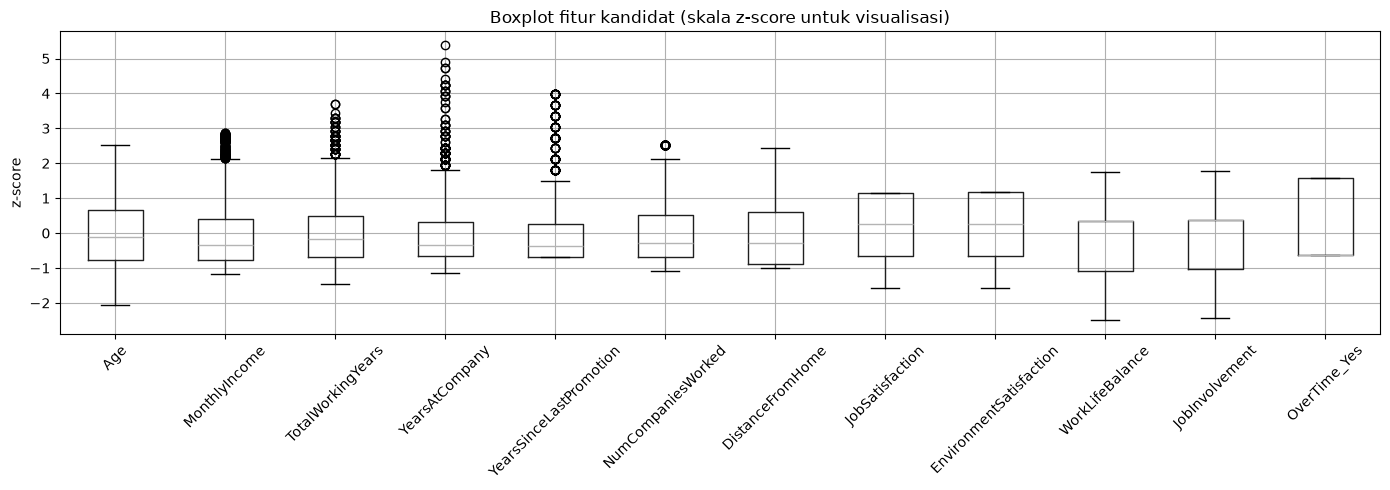

In [38]:
# Rumus z-score: (nilai - rata-rata) / standar deviasi.
z_score_visualisasi = (X - X.mean()) / X.std()

plt.figure(figsize=(14, 5))
z_score_visualisasi.boxplot(rot=45)
plt.title("Boxplot fitur kandidat (skala z-score untuk visualisasi)")
plt.ylabel("z-score")
plt.tight_layout()
plt.show()

**Temuan.** Beberapa atribut numerik menunjukkan titik di luar batas boxplot, terutama fitur yang memiliki sebaran menceng.

**Interpretasi.** Titik di luar pagar boxplot mengindikasikan nilai ekstrem berdasarkan kriteria statistik, tetapi tidak membuktikan kesalahan data. Karakteristik observasi tersebut perlu diperiksa lebih lanjut.

**Keputusan.** Data ekstrem dipertahankan pada tahap ini. Dampak pencilan terhadap hasil K-Means akan dievaluasi pada eksperimen.

### 6c. Pemeriksaan kebutuhan penskalaan

K-Means menggunakan jarak Euclidean sehingga perbedaan satuan dan skala antarfitur berpengaruh terhadap pembentukan klaster. Perbandingan standar deviasi digunakan untuk menunjukkan ketimpangan skala atribut.

In [39]:
# Standar deviasi membantu membandingkan skala variasi antarkolom.
tabel_skala = pd.DataFrame({
    "minimum": X.min(),
    "maksimum": X.max(),
    "standar_deviasi": X.std().round(2),
}).sort_values("standar_deviasi", ascending=False)

display(tabel_skala)
rasio_skala = X.std().max() / X.std().min()
print(f"Rasio standar deviasi terbesar/terkecil: {rasio_skala:.0f}x")

,minimum,maksimum,standar_deviasi
MonthlyIncome,1009,19999,4707.96
Age,18,60,9.14
DistanceFromHome,1,29,8.11
TotalWorkingYears,0,40,7.78
YearsAtCompany,0,40,6.13
YearsSinceLastPromotion,0,15,3.22
NumCompaniesWorked,0,9,2.50
JobSatisfaction,1,4,1.10
EnvironmentSatisfaction,1,4,1.09
WorkLifeBalance,1,4,0.71


Rasio standar deviasi terbesar/terkecil: 10448x


**Temuan.** `MonthlyIncome` memiliki standar deviasi sekitar **4.708**, sedangkan atribut kepuasan memiliki standar deviasi mendekati **1**. Perbedaan tersebut menunjukkan skala variasi yang jauh berbeda antarfitur.

**Interpretasi.** Jika digunakan tanpa penskalaan, perbedaan nilai pada atribut pendapatan dapat mendominasi perhitungan jarak dibandingkan skor kepuasan atau fitur biner.

**Keputusan.** Penskalaan dengan `StandardScaler` direncanakan untuk matriks fitur pada tahap pemodelan. Data bersih tetap disimpan dalam nilai asalnya agar dapat digunakan untuk interpretasi.

### 6d. Distribusi `Attrition` sebagai informasi pendukung

Kolom `Attrition` diperiksa untuk mengetahui proporsi karyawan yang berstatus keluar (`Yes`) dan tetap bekerja (`No`). Analisis ini bersifat **deskriptif**, bukan pengukuran akurasi K-Means.

Jumlah per kategori:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Persentase per kategori:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


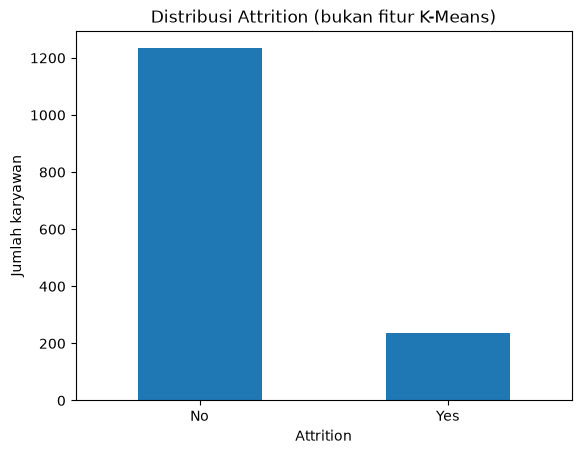

In [40]:
jumlah_attrition = df["Attrition"].value_counts()
persen_attrition = df["Attrition"].value_counts(normalize=True) * 100

print("Jumlah per kategori:")
print(jumlah_attrition)
print("\nPersentase per kategori:")
print(persen_attrition.round(2))

jumlah_attrition.plot.bar(rot=0)
plt.ylabel("Jumlah karyawan")
plt.title("Distribusi Attrition (bukan fitur K-Means)")
plt.show()

**Temuan.** Dari **1.470 karyawan**, sebanyak **237 (16,12%)** memiliki `Attrition=Yes`, sedangkan **1.233 (83,88%)** memiliki `Attrition=No`.

**Interpretasi.** Mayoritas karyawan pada dataset berstatus tidak keluar. Distribusi ini tidak menjadi label pelatihan K-Means dan tidak dapat digunakan sebagai ukuran keberhasilan clustering.

**Pemanfaatan.** Setelah klaster terbentuk, persentase `Attrition=Yes` pada tiap klaster dapat ditampilkan sebagai karakteristik tambahan, tanpa menyimpulkan hubungan sebab-akibat.

## Langkah 7 — Keputusan praproses dan penyimpanan data bersih

Hasil EDA digunakan untuk menetapkan perubahan yang diperlukan sebelum pemodelan. Keputusan dicatat bersama alasan dan dampaknya agar proses dapat ditelusuri kembali oleh anggota kelompok.

Dataset bersih tetap menyimpan kolom yang berguna untuk identifikasi dan interpretasi. Oleh karena itu, `data_bersih.csv` **tidak sama** dengan matriks fitur `X` yang akan dimasukkan ke K-Means.

In [41]:
# Tiga kolom ini konstan sehingga tidak memberikan variasi data.
kolom_dibuang = ["EmployeeCount", "StandardHours", "Over18"]
df_bersih = df.drop(columns=kolom_dibuang).copy()

# Konversi kolom teks ke category untuk dokumentasi dan analisis lokal.
# Ketika disimpan ke CSV, tipe category akan dibaca kembali sebagai teks.
for nama_kolom in df_bersih.select_dtypes(include="object").columns:
    df_bersih[nama_kolom] = df_bersih[nama_kolom].astype("category")

# Tambahkan kolom biner dari kategori lembur Yes/No.
df_bersih["OverTime_Yes"] = (df_bersih["OverTime"] == "Yes").astype(int)

print("Ukuran sebelum pembersihan :", df.shape)
print("Ukuran sesudah pembersihan :", df_bersih.shape)
assert df_bersih.shape[0] == df.shape[0], "Jumlah baris berubah; periksa proses!"

Ukuran sebelum pembersihan : (1470, 35)
Ukuran sesudah pembersihan : (1470, 33)


In [42]:
# Catat apa yang ditemukan, apa tindakan yang diambil, dan mengapa.
# Ini contoh tabel audit keputusan yang langsung merujuk hasil penghitungan.
tabel_keputusan = pd.DataFrame([
    {
        "kolom / baris": ", ".join(kolom_dibuang),
        "temuan": "Konstan (hanya satu nilai unik)",
        "keputusan": "Dikeluarkan dari data bersih",
        "alasan": "Tidak membedakan profil karyawan",
    },
    {
        "kolom / baris": "EmployeeNumber",
        "temuan": f"{df['EmployeeNumber'].nunique()} nilai unik",
        "keputusan": "Disimpan untuk penelusuran, bukan fitur",
        "alasan": "Nomor identitas tidak memberi makna jarak",
    },
    {
        "kolom / baris": "Nilai hilang",
        "temuan": f"{int(df.isna().sum().sum())} sel kosong",
        "keputusan": "Tidak ada imputasi jika hasil nol",
        "alasan": "Tidak perlu mengubah nilai yang tidak hilang",
    },
    {
        "kolom / baris": "Duplikat",
        "temuan": f"{jumlah_duplikat} baris identik",
        "keputusan": "Tidak membuang jika hasil nol",
        "alasan": "Tidak ada duplikasi yang terdeteksi",
    },
    {
        "kolom / baris": "Pencilan numerik",
        "temuan": "Kandidat pencilan ditemukan melalui IQR",
        "keputusan": "Dipertahankan untuk analisis berikutnya",
        "alasan": "Pencilan tidak sama dengan nilai mustahil",
    },
    {
        "kolom / baris": "Attrition",
        "temuan": "Label status keluar/tidak keluar",
        "keputusan": "Bahan interpretasi, bukan fitur X",
        "alasan": "K-Means harus mengelompokkan tanpa target",
    },
    {
        "kolom / baris": "OverTime",
        "temuan": "Kategori Yes/No",
        "keputusan": "Buat OverTime_Yes (0/1)",
        "alasan": "K-Means memerlukan fitur numerik",
    },
])

display(tabel_keputusan)

,kolom / baris,temuan,keputusan,alasan
0,"EmployeeCount, StandardHours, Over18",Konstan (hanya satu nilai unik),Dikeluarkan dari data bersih,Tidak membedakan profil karyawan
1,EmployeeNumber,1470 nilai unik,"Disimpan untuk penelusuran, bukan fitur",Nomor identitas tidak memberi makna jarak
2,Nilai hilang,0 sel kosong,Tidak ada imputasi jika hasil nol,Tidak perlu mengubah nilai yang tidak hilang
3,Duplikat,0 baris identik,Tidak membuang jika hasil nol,Tidak ada duplikasi yang terdeteksi
4,Pencilan numerik,Kandidat pencilan ditemukan melalui IQR,Dipertahankan untuk analisis berikutnya,Pencilan tidak sama dengan nilai mustahil
5,Attrition,Label status keluar/tidak keluar,"Bahan interpretasi, bukan fitur X",K-Means harus mengelompokkan tanpa target
6,OverTime,Kategori Yes/No,Buat OverTime_Yes (0/1),K-Means memerlukan fitur numerik


### Penyusunan kamus data

Kamus data memuat nama atribut, arti, satuan, tipe, peran dalam analisis, dan catatan kualitas. Satuan yang belum terverifikasi dicatat secara eksplisit agar penafsiran data tidak melampaui informasi yang tersedia.

In [43]:
# Setiap entri berisi: (arti, satuan, tipe, peran)
kamus_kolom = {
    "Age": ("Usia karyawan", "tahun", "numerik bulat", "fitur"),
    "Attrition": ("Status keluar (Yes/No)", "-", "kategori", "bahan interpretasi"),
    "BusinessTravel": ("Frekuensi perjalanan dinas", "-", "kategori", "bahan interpretasi"),
    "DailyRate": ("Nilai DailyRate; definisi bisnis belum jelas", "belum terverifikasi", "numerik", "tidak dipakai"),
    "Department": ("Departemen", "-", "kategori", "bahan interpretasi"),
    "DistanceFromHome": ("Jarak tempat tinggal dari kantor", "belum terverifikasi", "numerik bulat", "fitur"),
    "Education": ("Tingkat pendidikan", "kode ordinal 1-5", "ordinal", "bahan interpretasi"),
    "EducationField": ("Bidang pendidikan", "-", "kategori", "bahan interpretasi"),
    "EmployeeNumber": ("Nomor karyawan", "-", "identifier", "identifier"),
    "EnvironmentSatisfaction": ("Kepuasan lingkungan kerja", "skor 1-4", "ordinal", "fitur"),
    "Gender": ("Jenis kelamin", "-", "kategori", "bahan interpretasi"),
    "HourlyRate": ("Nilai HourlyRate; definisi bisnis belum jelas", "belum terverifikasi", "numerik", "tidak dipakai"),
    "JobInvolvement": ("Keterlibatan kerja", "skor 1-4", "ordinal", "fitur"),
    "JobLevel": ("Tingkat jabatan", "kode ordinal 1-5", "ordinal", "bahan interpretasi"),
    "JobRole": ("Jenis pekerjaan", "-", "kategori", "bahan interpretasi"),
    "JobSatisfaction": ("Kepuasan kerja", "skor 1-4", "ordinal", "fitur"),
    "MaritalStatus": ("Status pernikahan", "-", "kategori", "bahan interpretasi"),
    "MonthlyIncome": ("Pendapatan bulanan", "mata uang belum terverifikasi", "numerik bulat", "fitur"),
    "MonthlyRate": ("Nilai MonthlyRate; definisi bisnis belum jelas", "belum terverifikasi", "numerik", "tidak dipakai"),
    "NumCompaniesWorked": ("Jumlah perusahaan tempat bekerja", "perusahaan", "numerik bulat", "fitur"),
    "OverTime": ("Status lembur", "-", "kategori biner", "sumber fitur turunan"),
    "PercentSalaryHike": ("Persentase kenaikan gaji", "%", "numerik bulat", "tidak dipakai"),
    "PerformanceRating": ("Penilaian kinerja", "kode ordinal", "ordinal", "tidak dipakai"),
    "RelationshipSatisfaction": ("Kepuasan hubungan kerja", "skor 1-4", "ordinal", "tidak dipakai"),
    "StockOptionLevel": ("Tingkat opsi saham", "kode ordinal", "ordinal", "tidak dipakai"),
    "TotalWorkingYears": ("Total lama bekerja", "tahun", "numerik bulat", "fitur"),
    "TrainingTimesLastYear": ("Jumlah pelatihan tahun lalu", "kali", "numerik bulat", "tidak dipakai"),
    "WorkLifeBalance": ("Keseimbangan kerja dan kehidupan", "skor 1-4", "ordinal", "fitur"),
    "YearsAtCompany": ("Lama bekerja di perusahaan", "tahun", "numerik bulat", "fitur"),
    "YearsInCurrentRole": ("Lama bekerja pada posisi saat ini", "tahun", "numerik bulat", "tidak dipakai"),
    "YearsSinceLastPromotion": ("Lama sejak promosi terakhir", "tahun", "numerik bulat", "fitur"),
    "YearsWithCurrManager": ("Lama bekerja dengan manajer saat ini", "tahun", "numerik bulat", "tidak dipakai"),
    "OverTime_Yes": ("Indikator lembur, 1=Yes, 0=No", "-", "biner", "fitur"),
}

kamus = pd.DataFrame(
    [[nama, *isi, "tidak ada nilai hilang pada pemeriksaan awal"]
     for nama, isi in kamus_kolom.items()],
    columns=["Nama kolom", "Arti", "Satuan", "Tipe ditetapkan", "Peran", "Catatan mutu"],
)

# Mencegah kolom terlewat atau salah eja.
assert set(kamus_kolom) == set(df_bersih.columns), (
    set(kamus_kolom) ^ set(df_bersih.columns)
)
display(kamus)

,Nama kolom,Arti,Satuan,Tipe ditetapkan,Peran,Catatan mutu
0,Age,Usia karyawan,tahun,numerik bulat,fitur,tidak ada nilai hilang pada pemeriksaan awal
1,Attrition,Status keluar (Yes/No),-,kategori,bahan interpretasi,tidak ada nilai hilang pada pemeriksaan awal
2,BusinessTravel,Frekuensi perjalanan dinas,-,kategori,bahan interpretasi,tidak ada nilai hilang pada pemeriksaan awal
3,DailyRate,Nilai DailyRate; definisi bisnis belum jelas,belum terverifikasi,numerik,tidak dipakai,tidak ada nilai hilang pada pemeriksaan awal
4,Department,Departemen,-,kategori,bahan interpretasi,tidak ada nilai hilang pada pemeriksaan awal
5,DistanceFromHome,Jarak tempat tinggal dari kantor,belum terverifikasi,numerik bulat,fitur,tidak ada nilai hilang pada pemeriksaan awal
6,Education,Tingkat pendidikan,kode ordinal 1-5,ordinal,bahan interpretasi,tidak ada nilai hilang pada pemeriksaan awal
7,EducationField,Bidang pendidikan,-,kategori,bahan interpretasi,tidak ada nilai hilang pada pemeriksaan awal
8,EmployeeNumber,Nomor karyawan,-,identifier,identifier,tidak ada nilai hilang pada pemeriksaan awal
9,EnvironmentSatisfaction,Kepuasan lingkungan kerja,skor 1-4,ordinal,fitur,tidak ada nilai hilang pada pemeriksaan awal


In [44]:
# Simpan seluruh hasil ke folder data/, bukan ke folder notebook/.
path_data_bersih = folder_data / "data_bersih.csv"
path_kamus = folder_data / "kamus_data.csv"

df_bersih.to_csv(path_data_bersih, index=False)
kamus.to_csv(path_kamus, index=False)

print("Dataset bersih:", path_data_bersih)
print("Kamus data     :", path_kamus)
print("Ukuran data bersih:", df_bersih.shape)
print("Jumlah entri kamus:", len(kamus))

Dataset bersih: ..\data\data_bersih.csv
Kamus data     : ..\data\kamus_data.csv
Ukuran data bersih: (1470, 33)
Jumlah entri kamus: 33


## Ringkasan hasil EDA dan rencana tahap berikutnya

**Ringkasan temuan:**

- Dataset awal terdiri atas **1.470 baris dan 35 kolom**. Pemeriksaan awal tidak menemukan nilai hilang (`NaN`) maupun duplikat baris.
- Terdapat tiga kolom konstan (`EmployeeCount`, `StandardHours`, `Over18`) yang dikeluarkan dari dataset bersih. Sebuah indikator biner `OverTime_Yes` ditambahkan sehingga data bersih menjadi **1.470 baris dan 33 kolom**.
- `EmployeeNumber` dipertahankan sebagai identifier untuk penelusuran, tetapi tidak digunakan sebagai fitur. Kolom `Attrition` hanya menjadi bahan interpretasi.
- Pemeriksaan IQR menemukan kandidat pencilan, antara lain **114 baris (7,8%)** pada `MonthlyIncome`. Nilai ekstrem tidak dihapus otomatis.
- Korelasi beberapa atribut pengalaman dan pendapatan mengindikasikan adanya dimensi senioritas yang saling berkaitan. Hal ini menjadi dasar pertimbangan pemilihan fitur.

**Keterbatasan analisis:** dataset bersifat sintetis; sejumlah skor ordinal diperlakukan sebagai numerik; dan beberapa satuan atribut belum dapat dipastikan. Temuan bersifat deskriptif serta tidak digunakan untuk menyimpulkan penyebab keluarnya karyawan.

**Rencana tahap pemodelan:** menyiapkan fitur yang disepakati, menerapkan penskalaan, menguji nilai K menggunakan *Elbow Method* (K=2–10), memvalidasi dengan *Silhouette Score*, lalu membandingkan hasil pada dua himpunan fitur. Profil tiap klaster akan dijelaskan menggunakan statistik yang relevan sebelum penyusunan aplikasi web.